Цель задания: Спроектировать и реализовать объектную модель учёта банковских операций с опорой на материалы тем 1–5 (файлы, datetime, pandas, регулярные выражения, ООП).

## Контекст
Нужна небольшая модель учёта банковских счетов: расчётный и сберегательный счёт. Система должна вести историю операций, валидировать входные данные, отличать успешные операции от отклонённых и давать простую аналитику.

Решение оформите в объектно-ориентированном стиле. Опирайтесь на материалы тем 1–5. Конкретную структуру классов, имена методов и способ хранения данных выбираете вы - важно, чтобы поведение системы соответствовало правилам ниже и чтобы демонстрация в ноутбуке это подтверждала.

## Задание 1.
Реализуйте модель банковского счёта, которая не только меняет баланс, но и ведёт детальную историю действий.

### Этап 1.
**Правила**
* Счёт открывается с именем владельца и начальным балансом. Начальный баланс не может быть отрицательным (по умолчанию - 0).
* Номер счёта формируется автоматически в формате ACC-XXXX, где XXXX - порядковый номер. Счётчик номеров начинается с 1000. Номера счетов должны быть уникальными.
* Поддерживаются операции пополнения и снятия:
1. Сумма операции должна быть положительной.
2. Некорректная сумма приводит к исключению.
3. При успехе баланс обновляется, в историю добавляется запись со статусом успешной операции.
4. Если средств недостаточно, баланс не меняется, но попытка обязательно фиксируется в истории со статусом неуспешной операции.

* Каждая запись истории — структурированные данные. Минимум полей: тип операции (deposit / withdraw), сумма, дата и время, баланс после операции, статус (success / fail). Для даты и времени используйте модуль datetime.
* Должна быть возможность узнать текущий баланс и получить историю операций в удобном для чтения виде.

### Демонстрация
В ноутбуке покажите:
- создание счёта;
- несколько успешных пополнений и снятий;
- хотя бы одну неуспешную попытку снятия;
- вывод баланса и истории.

### Этап 2.
По истории операций постройте линейный график изменения баланса во времени (ось X - время операции, ось Y - баланс после операции). У графика должны быть заголовок и подписи осей.

In [1]:
import re
import time
from datetime import datetime
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

In [2]:
class Account:
    """
    Модель банковского счета:
    создание, изменение баланса и ведение истории
    """

    _start_account_number = 1000

    def __init__(self, name, balance=0):
        self._check_name(name)
        self._check_number(
            balance,
            error_text='Начальный баланс',
            start_flag=True)
        self.name = name
        self._balance = round(balance, 2)
        self.account_number = f'ACC-{Account._start_account_number:04d}'
        Account._start_account_number += 1
        self._history = []

    @staticmethod
    def _check_name(name):
        """
        Проверка имена владельца счета.
        Статический метод без ссылок на self.
        
        Проверяем, что введенное имя владельца счета
        является не пустой строкой
        """
        if not isinstance(name, str) or not name.strip():
            raise ValueError('Имя владельца должно быть не пустой строкой')

    @staticmethod
    def _check_number(value, error_text, start_flag=False):
        """
        Проверка вводимых чисел.
        Статический метод без ссылок на self.
        
        Проверяем, что вводимое значение (начальный баланс,
        сумма операции и т.д.) является числом.
        Начальный баланс может быть равен 0 (дефолтно) или
        положительному числу,
        остальные числовые значения должны быть больше 0
        """
        if isinstance(value, bool) or not isinstance(value, (int, float)):
            raise ValueError(f'{error_text} не является числом')
        if start_flag:
            if value < 0:
                raise ValueError(
                    'Начальный баланс не может быть отрицательным'
                )
        else:
            if value <= 0:
                raise ValueError(
                    f'{error_text} - значение должно быть больше нуля'
                )

    def _history_record(self, operation, amount, status):
        """
        Добавление записи к истории операций.
        
        record - запись в истории, собирается из типа операции,
        суммы операции, даты и времени в формате datetime, 
        баланса после операции и статуса.
        Дата и время операции и баланс определяются автоматически,
        остальные параметры задаются на входе
        """
        record = {
            'operation': operation,
            'amount': round(amount, 2),
            'date': datetime.now().replace(microsecond=0),
            'balance_after': self._balance,
            'status': status
        }
        self._history.append(record)

    def deposit(self, amount):
        """
        Операция пополнения счета.
        Некорректные суммы исключаются и не отражаются в истории.
        Увеличение баланса счета на введенную сумму операции
        amount. Успешные операции записываются в историю со
        статусом success.
        """
        self._check_number(amount, error_text='Сумма операции')
        self._balance = round(self._balance + amount, 2)
        self._history_record('deposit', amount, 'success')
        print(f'Успешное пополнение на {round(amount, 2)}')

    def withdraw(self, amount):
        """
        Операция снятия со счета. 
        Некорректные суммы исключаются и не отражаются в истории. 
        Уменьшение баланса счета на введенную сумму операции
        amount. Успешные операции записываются в историю со
        статусом success.
        Если сумма операции > текущего баланса, баланс не обновляем,
        а операция отражается в истории со статусом fail
        """
        self._check_number(amount, error_text='Сумма операции')
        if amount > self._balance:
            self._history_record('withdraw', amount, 'fail')
            print('Недостаточно средств')
        else:
            self._balance = round(self._balance - amount, 2)
            self._history_record('withdraw', amount, 'success')
            print(f'Успешное снятие на {round(amount, 2)}')

    def current_balance(self):
        """Показывает текущий баланс"""
        print(f'Текущий баланс = {self._balance}')

    def _history_to_df(self):
        """
        Преобразование истории операций в pd dataframe.
        """
        df_history = pd.DataFrame(self._history)
        df_history.rename(
            columns={
                'operation': 'Тип операции',
                'amount': 'Сумма',
                'date': 'Дата и время',
                'balance_after': 'Баланс после операции',
                'status': 'Статус'
        }, 
            inplace=True
        )
        return df_history

    def get_history(self):
        """
        Вывод истории операций в удобном для чтения виде.
        Если операций по счету не было, выводит сообщение.
        """
        if not self._history:
            print('Пока нет операций')
            return
        else:
            print('История операций')
            return self._history_to_df()

    def balance_plot(self):
        """Вывод линейного графика изменения баланса"""
        if not self._history:
            print('Пока нет операций')
            return

        fig, ax = plt.subplots(figsize=(12, 6))
        sns.lineplot(
            data=self._history_to_df(),
            x='Дата и время',
            y='Баланс после операции',
            marker='o',
            linewidth=4,
            estimator=None,
            sort=False,
            ax=ax
        )

        ax.set_title('Изменение баланса', fontsize=18)
        ax.set_xlabel('Время операции', fontsize=14)
        ax.set_ylabel('Баланс после операции', fontsize=14)

        ax.grid(True)
        fig.autofmt_xdate(rotation=90)
        fig.tight_layout()
        plt.show()

### Создание счета

In [3]:
account_1 = Account(name='Стэн Смит', balance=200)
print(f'Номер счета: {account_1.account_number}')

Номер счета: ACC-1000


### Несколько успешных пополнений и снятий

In [4]:
account_1.deposit(amount=100)
time.sleep(1)
account_1.deposit(amount=30.45)
time.sleep(1)
account_1.withdraw(amount=80.123654987)
time.sleep(1)
account_1.withdraw(amount=10.5)

Успешное пополнение на 100
Успешное пополнение на 30.45
Успешное снятие на 80.12
Успешное снятие на 10.5


### Неуспешные попытки снятия

In [5]:
account_1.withdraw(amount=450)
time.sleep(1)
account_1.withdraw(amount=300.9)

Недостаточно средств
Недостаточно средств


### Вывод баланса и истории

In [6]:
account_1.current_balance()
account_1.get_history()

Текущий баланс = 239.83
История операций


,Тип операции,Сумма,Дата и время,Баланс после операции,Статус
0,deposit,100.00,2026-10-23 19:03:13,300.00,success
1,deposit,30.45,2026-10-23 19:03:14,330.45,success
2,withdraw,80.12,2026-10-23 19:03:15,250.33,success
3,withdraw,10.50,2026-10-23 19:03:16,239.83,success
4,withdraw,450.00,2026-10-23 19:03:16,239.83,fail
5,withdraw,300.90,2026-10-23 19:03:17,239.83,fail


### График для этапа 2

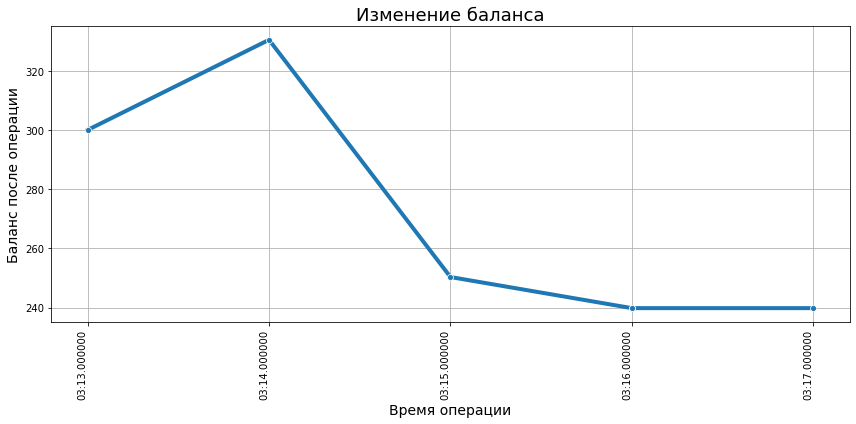

In [7]:
account_1.balance_plot()

## Задание 2. Разные типы счетов и аналитика
Расчётный и сберегательный счета должны отражать общее поведение учёта операций, но отличаться правилами.

### Правила
* Расчётный счёт - базовые пополнение и снятие без дополнительных ограничений на долю снимаемой суммы.
* Сберегательный счёт: умеет начислять проценты на текущий остаток (ставку задаёт вызывающий код, например 7%); нельзя снять больше 50% текущего баланса; нарушающая правило попытка не меняет баланс и фиксируется в истории как неуспешная.
* У каждого типа счёта должен быть различимый тип (чтобы по объекту/данным было понятно, расчётный это счёт или сберегательный).
* Валидация имени владельца: формат «Имя Фамилия», слова с заглавной буквы, кириллица или латиница. Иначе - исключение. Для проверки используйте регулярные выражения.
* Аналитика по истории: возможность получить последние N крупных успешных операций (порог «крупности» и N задаёт вызывающий код).

### Демонстрация
В ноутбуке покажите:
- создание расчётного и сберегательного счета;
- покажите начисление процентов на сберегательном;
- покажите отклонение снятия сверх 50% на сберегательном;
- покажите выборку последних крупных операций;
- покажите реакцию на некорректное имя владельца и/или некорректную сумму.

### Дополнительное задание. Перевод между счетами
Добавьте возможность перевода средств с одного счёта на другой:

* при успехе сумма списывается у отправителя и зачисляется получателю;
* если списание у отправителя невозможно (недостаточно средств или сработали ограничения сберегательного счёта), баланс получателя не меняется;
* в историях обоих счетов перевод должен быть различим (например, общий идентификатор перевода, связанные записи или иной явный признак - способ выбираете вы).

In [8]:
class UpdatedAccount(Account):
    """Дополненный класс для создания новых типов счетов"""
    account_type = 'basic'
    
    _start_transfer_number = 1

    @staticmethod
    def _check_name(name):
        """
        Переопределяем метод, добавляя условия по заданию 2:
        Сначала выполняется базовая проверка на не пустые строки,
        далее валидация имени владельца: формат «Имя Фамилия»,
        слова с заглавной буквы, кириллица или латиница.
        Иначе - исключение
        """
        Account._check_name(name)

        name_pattern = (
            r'(?:[А-ЯЁ][а-яё]+ [А-ЯЁ][а-яё]+|'
            r'[A-Z][a-z]+ [A-Z][a-z]+)'
        )
        if re.fullmatch(name_pattern, name) is None:
            raise ValueError('Некорректный формат имени')
    
    def get_n_transactions(self, threshold, n):
        """
        Получение последних N крупных успешных операций
        """
        self._check_number(threshold, error_text='Порог "крупности"')
        if isinstance(n, bool) or not isinstance(n, int) or n <= 0:
            raise ValueError(
                'n должно быть целым положительным целым числом'
            )

        if not self._history:
            print('Пока нет операций')
            return

        df = self._history_to_df()
        df_filtered = df.loc[
            (df['Статус'] == 'success') &
            (df['Сумма'] >= threshold)
        ]
        return df_filtered.tail(n)
    
    def _history_to_df(self):
        """
        Добавляем в историю операций новые поля
        с ID перевода и счетом получателя
        """
        df_history = super()._history_to_df()
        return df_history.rename(columns={'transfer_id': 'ID перевода'})

    def transfer_to(self, amount, beneficiary):
        """
        Перевод на другой счёт.
        ПРоверяем существование счета получателя,
        счет получателя не может совпадать со счетом отправителя.
        Для каждого перевода формируем уникальный id.
        Успешные переводы отражаются в истории обоих счетов,
        неудачные переводы отражаются в истории отправителя
        со статусом fail.
        """
        if not isinstance(beneficiary, Account):
            raise ValueError('Такого счета не существует')
        if beneficiary is self:
            raise ValueError(
                'Счет получателя не может совпадать со счетом отправителя'
            )
        self._check_number(amount, error_text='Сумма перевода')

        transfer_id = f'TR-ID-{UpdatedAccount._start_transfer_number}'
        UpdatedAccount._start_transfer_number += 1
        
        self.withdraw(amount)
        sender_record = self._history[-1]
        sender_record['transfer_id'] = transfer_id
        if sender_record['status'] == 'fail':
            print('Перевод отклонён')
            return

        beneficiary.deposit(amount)
        beneficiary_record = beneficiary._history[-1]
        beneficiary_record['transfer_id'] = transfer_id
        print(f'Успешный перевод на счет {beneficiary.account_number}')
        return

In [9]:
class CheckingAccount(UpdatedAccount):
    """
    Создание расчетного счета.
    Полностью повторяет функционал родительского класса
    """
    account_type = 'checking'

In [10]:
class SavingsAccount(UpdatedAccount):
    """
    Создание сберегательного счета.
    Добавлены ограничения на снятие средств и
    возможность начисления процентов
    """
    account_type = 'savings'

    def save_interest(self, interest_rate):
        """
        Начисление процентов на текущий остаток.
        Предполагаем, что проценты начисляем сразу за год
        """
        self._check_number(interest_rate, error_text='Ставка')
        interest = round(self._balance * interest_rate / 100, 2)
        if interest <= 0:
            print('Проценты не начисляются')
            return
        self._balance = round(self._balance + interest, 2)
        self._history_record('interest', interest, 'success')
        print(f'{interest} начислено процентами по ставке {interest_rate}%')

    def withdraw(self, amount):
        """
        Добавление ограничения для сберегательного счета:
        За операцию нельзя снять больше 50% текущего баланса
        """
        self._check_number(amount, error_text='Сумма операции')
        max_withdraw_share = 0.5
        withdraw_limit = self._balance * max_withdraw_share
        if self._balance >= amount > withdraw_limit:
            self._history_record('withdraw', amount, 'fail')
            print(f'Нельзя снять больше {withdraw_limit:.2f}')
            return
        else:
            super().withdraw(amount)

### Создание расчётного и сберегательного счета

In [11]:
account_2 = CheckingAccount(name='Francine Smith', balance=450)
print(f'Номер счета {account_2.account_number}'
      f' с типом {account_2.account_type}')
account_3 = SavingsAccount(name='Роджер Смит', balance=600.5)
print(f'Номер счета {account_3.account_number}'
      f' с типом {account_3.account_type}')

Номер счета ACC-1001 с типом checking
Номер счета ACC-1002 с типом savings


### Начисление процентов на сберегательном счете

In [12]:
account_3.save_interest(interest_rate=13)

78.06 начислено процентами по ставке 13%


### Отклонение снятия сверх 50% на сберегательном счете

In [13]:
account_3.withdraw(amount=700)
time.sleep(1)
account_3.withdraw(amount=400)

Недостаточно средств
Нельзя снять больше 339.28


### Выборка последних крупных операций

In [14]:
account_3.deposit(amount=85)
time.sleep(1)
account_3.deposit(amount=190)
time.sleep(1)
account_3.deposit(amount=50)
time.sleep(1)
account_3.withdraw(amount=1000)
time.sleep(1)
account_3.withdraw(amount=100)
time.sleep(1)
account_3.deposit(amount=250.5)
time.sleep(1)
account_3.withdraw(amount=95)
time.sleep(1)
account_3.withdraw(amount=70.77)

Успешное пополнение на 85
Успешное пополнение на 190
Успешное пополнение на 50
Нельзя снять больше 501.78
Успешное снятие на 100
Успешное пополнение на 250.5
Успешное снятие на 95
Успешное снятие на 70.77


In [15]:
account_3.get_history()

История операций


,Тип операции,Сумма,Дата и время,Баланс после операции,Статус
0,interest,78.06,2026-10-23 19:03:18,678.56,success
1,withdraw,700.00,2026-10-23 19:03:18,678.56,fail
2,withdraw,400.00,2026-10-23 19:03:19,678.56,fail
3,deposit,85.00,2026-10-23 19:03:19,763.56,success
4,deposit,190.00,2026-10-23 19:03:20,953.56,success
5,deposit,50.00,2026-10-23 19:03:21,1003.56,success
6,withdraw,1000.00,2026-10-23 19:03:22,1003.56,fail
7,withdraw,100.00,2026-10-23 19:03:23,903.56,success
8,deposit,250.50,2026-10-23 19:03:24,1154.06,success
9,withdraw,95.00,2026-10-23 19:03:25,1059.06,success


In [16]:
account_3.get_n_transactions(threshold=100, n=3)

,Тип операции,Сумма,Дата и время,Баланс после операции,Статус
4,deposit,190.0,2026-10-23 19:03:20,953.56,success
7,withdraw,100.0,2026-10-23 19:03:23,903.56,success
8,deposit,250.5,2026-10-23 19:03:24,1154.06,success


### Перевод с одного счета на другой

In [17]:
account_3.transfer_to(amount=120, beneficiary=account_2)

Успешное снятие на 120
Успешное пополнение на 120
Успешный перевод на счет ACC-1001


In [18]:
account_3.transfer_to(amount=3000, beneficiary=account_2)

Недостаточно средств
Перевод отклонён


In [19]:
account_3.get_history()

История операций


,Тип операции,Сумма,Дата и время,Баланс после операции,Статус,ID перевода
0,interest,78.06,2026-10-23 19:03:18,678.56,success,NaN
1,withdraw,700.00,2026-10-23 19:03:18,678.56,fail,NaN
2,withdraw,400.00,2026-10-23 19:03:19,678.56,fail,NaN
3,deposit,85.00,2026-10-23 19:03:19,763.56,success,NaN
4,deposit,190.00,2026-10-23 19:03:20,953.56,success,NaN
5,deposit,50.00,2026-10-23 19:03:21,1003.56,success,NaN
6,withdraw,1000.00,2026-10-23 19:03:22,1003.56,fail,NaN
7,withdraw,100.00,2026-10-23 19:03:23,903.56,success,NaN
8,deposit,250.50,2026-10-23 19:03:24,1154.06,success,NaN
9,withdraw,95.00,2026-10-23 19:03:25,1059.06,success,NaN


In [20]:
account_2.get_history()

История операций


,Тип операции,Сумма,Дата и время,Баланс после операции,Статус,ID перевода
0,deposit,120,2026-10-23 19:03:26,570,success,TR-ID-1


### Реакция на некорректное имя владельца и/или некорректную сумму

**Некорректное имя**

In [21]:
test_names = [
    123, 
    ' ', 
    'стив Смит', 
    'Jeff', 
    'Klaus Смит',
    ' Hayley Smith', 
    'Rogu Smith 1'
]

for test_name in test_names:
    try:
        CheckingAccount(test_name)
    except ValueError as error:
        print(f'{test_name!r:15} | {error}')
        print('-' * 75)

123             | Имя владельца должно быть не пустой строкой
---------------------------------------------------------------------------
' '             | Имя владельца должно быть не пустой строкой
---------------------------------------------------------------------------
'стив Смит'     | Некорректный формат имени
---------------------------------------------------------------------------
'Jeff'          | Некорректный формат имени
---------------------------------------------------------------------------
'Klaus Смит'    | Некорректный формат имени
---------------------------------------------------------------------------
' Hayley Smith' | Некорректный формат имени
---------------------------------------------------------------------------
'Rogu Smith 1'  | Некорректный формат имени
---------------------------------------------------------------------------


**Некорректная сумма**

Начальный баланс

In [22]:
test_amounts = [-10.55, True, '123', None]
for amount in test_amounts:
    try:
        CheckingAccount('Стив Смит', amount)
    except ValueError as error:
        print(f'{amount!r:15} | {error}')
        print('-' * 75)

-10.55          | Начальный баланс не может быть отрицательным
---------------------------------------------------------------------------
True            | Начальный баланс не является числом
---------------------------------------------------------------------------
'123'           | Начальный баланс не является числом
---------------------------------------------------------------------------
None            | Начальный баланс не является числом
---------------------------------------------------------------------------


Операция

In [23]:
account_4 = SavingsAccount('Стив Смит', 50)

print('Пополнение счета')
print('-' * 75)
for amount in test_amounts:
    try:
        account_4.deposit(amount)
    except ValueError as error:
        print(f'{amount!r:15} | {error}')
        print('-' * 75)
        
print('Снятие со счета')
print('-' * 75)
for amount in test_amounts:
    try:
        account_4.withdraw(amount)
    except ValueError as error:
        print(f'{amount!r:15} | {error}')
        print('-' * 75)

print('Начисление процентов')
print('-' * 75)
for amount in test_amounts:
    try:
        account_4.save_interest(amount)
    except ValueError as error:
        print(f'{amount!r:15} | {error}')
        print('-' * 79)

Пополнение счета
---------------------------------------------------------------------------
-10.55          | Сумма операции - значение должно быть больше нуля
---------------------------------------------------------------------------
True            | Сумма операции не является числом
---------------------------------------------------------------------------
'123'           | Сумма операции не является числом
---------------------------------------------------------------------------
None            | Сумма операции не является числом
---------------------------------------------------------------------------
Снятие со счета
---------------------------------------------------------------------------
-10.55          | Сумма операции - значение должно быть больше нуля
---------------------------------------------------------------------------
True            | Сумма операции не является числом
---------------------------------------------------------------------------
'123'          

## Задание 3. Загрузка «грязных» данных
Перед началом работы загрузите из личного кабинета файлы transactions_dirty.csv и transactions_dirty.json.

Файл общий для нескольких счетов: нужно загружать в конкретный счёт только его операции (фильтрация по номеру счёта / типу - по данным файла).

### Правила
* Реализуйте загрузку истории из CSV и\или из JSON.
* Перед записью в историю отбрасывайте невалидные строки: опечатки в типе операции, пустые или отрицательные суммы, некорректные даты, некорректный статус и т.п.
* Для сберегательного счёта допустимы типы операций deposit, withdraw, interest; для расчётного - только deposit и withdraw. Операции, недопустимые для типа счёта, невалидны.
* После успешной загрузки валидных операций баланс счёта должен соответствовать последовательности принятых операций.

### Демонстрация
Загрузите данные хотя бы из одного формата в расчётный и в сберегательный счёт, покажите обновлённый баланс и фрагмент истории.

### Дополнительное задание. Отчёт об отбраковке
Помимо «молчаливого» отбрасывания мусора сформируйте явный результат очистки:
- сколько строк принято,
- сколько отклонено,
- почему отклонена каждая (или группа) строк - битая дата, пустая сумма, опечатка в типе (diposit), interest на расчётном счёте, неверный статус и т.д.

Формат отчёта на ваш выбор (список, датафрейм, печать сводки) - главное, чтобы его можно было показать в ноутбуке и по нему было понятно, что произошло с данными.

### Загрузка истории из JSON

In [24]:
json_file = 'transactions_dirty.json'
json_df = None
try:
    json_df = pd.read_json(json_file, convert_dates=False, dtype=False)
    print(f'Файл в формате JSON загружен, всего {len(json_df)} записей')
except FileNotFoundError:
    print(f'Файл {json_file} отсутствует в папке')

if json_df is not None:
    display(json_df.head(3))

Файл в формате JSON загружен, всего 105 записей


,account_number,account_type,date,operation,amount,balance_after,status
0,ACC-100001,checking,2025-09-27 22:17:26,deposit,921.0,2121.0,success
1,ACC-100001,checking,2025-09-27 22:17:26,deposit,607.0,2728.0,success
2,ACC-100001,checking,2025-09-28 22:17:26,deposit,488.0,3216.0,success


### Проверка исходных данных

**Общая информация**

In [25]:
json_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 105 entries, 0 to 104
Data columns (total 7 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   account_number  105 non-null    object 
 1   account_type    105 non-null    object 
 2   date            105 non-null    object 
 3   operation       103 non-null    object 
 4   amount          102 non-null    float64
 5   balance_after   105 non-null    float64
 6   status          105 non-null    object 
dtypes: float64(2), object(5)
memory usage: 5.9+ KB


In [26]:
print('Полных дубликатов:', json_df.duplicated().sum())
display(json_df[json_df.duplicated()])

Полных дубликатов: 5


,account_number,account_type,date,operation,amount,balance_after,status
100,ACC-100002,savings,09/10/2025 22:17,deposit,638.0,5241.27,success
101,ACC-100003,checking,2025-10-12 22:17:26,deposit,-115.0,3547.00,success
102,ACC-100004,savings,01/10/2025 22:17,withdraw,309.0,4247.00,success
103,ACC-100002,savings,2025-10-19 22:17:26,withdraw,300.0,6042.66,succes
104,ACC-100001,checking,2025-10-16 22:17:26,withdraw,393.0,7431.00,success


In [27]:
acc_len = json_df['account_number'].astype(str).map(len).unique()
print('Количество симвовлов в поле account_number =',
      acc_len)

Количество симвовлов в поле account_number = [10]


In [28]:
print('Тип счета по каждому счету')
account_types = pd.pivot_table(
    json_df[['account_number', 'account_type']],
    index=['account_number', 'account_type']
)

display(account_types)

Тип счета по каждому счету


,
account_number,account_type
ACC-100001,checking
ACC-100002,savings
ACC-100003,checking
ACC-100004,savings


В данных нет информации об имени владельца, при загрузке будут проставлено дефолтно "Имя Фамилия", чтобы не вводить для каждого счета данные вручную.

В поле `account_number` формат всех счетов представлен не в формате ACC-xxxx. Будут присвоены новые номера счетов с учетом ранее созданных номеров.

Есть пропуски в полях `operation` и `amount`, они будут исключены.

Есть 5 полных дубликатов, будут исключены (считаю ошибкой, т.к. `balance_after` должен был пересчитаться, даже если операции прошли практически одномоментно).

**Анализ категориальных полей**

In [29]:
cat_cols = ['account_type', 'operation', 'status']

print('Уникальные значения в категориальных полях:')
for col in cat_cols:
    print(f'{col!r:15}: {json_df[col].unique()}')

Уникальные значения в категориальных полях:
'account_type' : ['checking' 'savings']
'operation'    : ['deposit' 'withdraw' nan 'interest' 'diposit' 'wdraw']
'status'       : ['success' 'succes']


В `account_type` нет проблем, но в ранее созданных классах вывод типа счета не предусматривается, поэтому это поле не будет загружено.

В `operation` есть пропуски и некорректные названия для операций (diposit и wdraw), такие строки будут исключены.

В `status` есть некорректное значение succes, будет исключено.

**Анализ числоых полей**

In [30]:
num_cols = ['amount', 'balance_after']

print('Количество нулей и отрицательных значений:')
for col in num_cols:
    print(f'{col!r:15}:',
          f'{json_df.loc[json_df[col] <= 0].shape[0]}')

Количество нулей и отрицательных значений:
'amount'       : 6
'balance_after': 0


Помимо пропусков, в поле `amount` есть 6 нулевых/отрицательных значений, которые будут исключены.

**Проверка дат**

In [31]:
datetime_format = pd.to_datetime(
    json_df['date'],
    format='%Y-%m-%d %H:%M:%S',
    errors='coerce'
).notna()

display(json_df[datetime_format == False])

,account_number,account_type,date,operation,amount,balance_after,status
3,ACC-100001,checking,28/09/2025 22:17,deposit,129.00,3345.00,success
13,ACC-100001,checking,2025-17-34 12:00:00,deposit,793.00,5350.00,success
14,ACC-100001,checking,06/10/2025 22:17,withdraw,198.00,5152.00,success
17,ACC-100001,checking,2023-16-40 12:00:00,withdraw,111.00,6454.00,success
28,ACC-100002,savings,2023-22-32 12:00:00,deposit,797.00,2691.00,success
31,ACC-100002,savings,04/10/2025 22:17,interest,183.28,3848.83,success
35,ACC-100002,savings,09/10/2025 22:17,deposit,638.00,5241.27,success
69,ACC-100003,checking,2023-14-33 12:00:00,deposit,953.00,5888.00,success
81,ACC-100004,savings,01/10/2025 22:17,withdraw,309.00,4247.00,success
86,ACC-100004,savings,2024-17-35 12:00:00,deposit,533.00,6039.00,success


В поле `date` данные содержатся в разных форматах. Часть таких строк может быть преобразована в datetime, но другая часть содержит явные некорректные даты (например, 2023-16-40 12:00:00), которые будут исключены.

### Функции для загрузки данных

In [32]:
DEFAULT_NAME = 'Some Rando'


def change_date(row):
    """
    Перевод дат в datetime формат.
    В исходных данных 2 формата дат, подходящих
    для перевода в datetime.
    Если дата битая и не может быть переведена в
    datetime, возвращется None
    """
    date_formats = [
        '%Y-%m-%d %H:%M:%S',
        '%d/%m/%Y %H:%M'
    ]
    for date_format in date_formats:
        try:
            return datetime.strptime(row, date_format)
        except ValueError:
            continue
    return None


def check_data(row, account_type):
    """
    Построчная проверка данных из файла.
    Возвращает причину отбраковки для каждой ошибки.
    
    Сначала проверяется тип операции: он должен быть
    не пустым, название должно совпадать с типами из
    ранее созданного класса, также для каждого типа счета
    проверяется возможность проведения операции.
    Сумма операции: проверяется, что значение является числом,
    и значение > 0.
    Дата: проверяется, что исходная дата в строковом формате,
    для строк применяется функция change_dates.
    Статус операции: название должно соответствовать разрешенным
    из ранее созданного класса
    """
    all_operations = ['deposit', 'withdraw', 'interest']
    operations_dict = {
    'checking': ['deposit', 'withdraw'],
    'savings': ['deposit', 'withdraw', 'interest']
    }
    statuses = ['success', 'fail']
    excl_reason = []

    operation = row['operation']
    if pd.isna(operation):
        excl_reason.append('Нет типа операции')
    elif operation not in all_operations:
        excl_reason.append('Ошибочное название типа операции')
    elif operation not in operations_dict[account_type]:
        excl_reason.append('Операция недопустима для этого счета')
    
    amount = row['amount']
    if pd.isna(amount):
        excl_reason.append('Нет суммы операции')
    elif isinstance(amount, bool) or not isinstance(amount, (int, float)):
        excl_reason.append('Сумма операции не является числом')
    elif amount <= 0:
        excl_reason.append('Сумма операции нулевая или отрицательная')
    
    date = None
    if not isinstance(row['date'], str):
        excl_reason.append('Битая дата')
    else:
        date = change_date(row['date'])
        if date is None:
            excl_reason.append('Битая дата')

    if row['status'] not in statuses:
        excl_reason.append('Ошибочный статус')

    return excl_reason, date


def create_account(account_types, file_account_number, name=DEFAULT_NAME):
    """
    Создание счета нужного типа на основе типа счета
    из исходных данных.
    Для имени владельца счета ставим дефолтное значение
    """
    acc_classes = {
    'checking': CheckingAccount,
    'savings': SavingsAccount
    }
    types = account_types.loc[file_account_number].index
    account_type = types[0]
    return acc_classes[account_type](name)


def load_history(account, df, file_account_number):
    """
    Загрузка операций по счету.
    Невалидные строки не попадают в историю  изаписываются в отчёт.
    Баланс пересчитывается
    """
    rows = df[df['account_number'] == file_account_number]
    accepted = 0
    rejected = []
    duplicates_check = set()
    
    for index, row in rows.iterrows():
        invalid_rows, date = check_data(row, account.account_type)
        if not invalid_rows:
            key = (date, row['operation'], row['amount'],
                   row['balance_after'], row['status'])
            if key in duplicates_check:
                invalid_rows.append('Полный дубликат')
            elif (row['operation'] == 'withdraw'
                  and row['status'] == 'success'
                  and row['amount'] > account._balance):
                invalid_rows.append('Сумма операции больше баланса')
            else:
                duplicates_check.add(key)

        if invalid_rows:
            rejected.append({
                'Номер счета': row['account_number'],
                'Дата и время': row['date'],
                'Тип операции': row['operation'],
                'Сумма': row['amount'],
                'Статус': row['status'],
                'Причина исключения': '; '.join(invalid_rows)
            })
            continue
    
        amount = float(row['amount'])
        if row['status'] == 'success':
            if row['operation'] == 'withdraw':
                account._balance = round(account._balance - amount, 2)
            else:
                account._balance = round(account._balance + amount, 2)

        account._history_record(row['operation'], amount, row['status'])
        account._history[-1]['date'] = date
        accepted += 1

    return {
        'rows_total': len(rows),
        'rows_accepted': accepted,
        'rows_rejected': len(rejected),
        'rejected': pd.DataFrame(rejected)
    }


def load_account(df, account_types, file_account_number, name=DEFAULT_NAME):
    """Создание счета нужного типа и загрузка истории"""
    account = create_account(account_types, file_account_number, name)
    report = load_history(account, df, file_account_number)
    return account, report


def check_balance(account):
    """Проверка выполнения правила:
    После успешной загрузки валидных операций 
    баланс счёта должен соответствовать 
    последовательности принятых операций."""
    total = 0
    for record in account._history:
        if record['status'] != 'success':
            continue
        if record['operation'] == 'withdraw':
            total -= record['amount']
        else:
            total += record['amount']
    return round(total, 2) == account._balance

In [33]:
print('Исходные номера счетов:')
initial_accs = list(json_df['account_number'].unique())
print(initial_accs)

Исходные номера счетов:
['ACC-100001', 'ACC-100002', 'ACC-100003', 'ACC-100004']


**Загрузка данных**

In [34]:
json_1, json_1_report = load_account(json_df, account_types, 'ACC-100001')
json_2, json_2_report = load_account(json_df, account_types, 'ACC-100002')
json_3, json_3_report = load_account(json_df, account_types, 'ACC-100003')
json_4, json_4_report = load_account(json_df, account_types, 'ACC-100004')

**Вывод баланса и истории по каждому счету**

In [35]:
json_accs = [json_1, json_2, json_3, json_4]

for i in range(len(json_accs)):
    print(f'Счет {initial_accs[i]}')
    print(f'Новый номер счета {json_accs[i].account_number}')
    json_accs[i].current_balance()
    print()
    display(json_accs[i].get_history())
    print('-' * 75)

Счет ACC-100001
Новый номер счета ACC-1004
Текущий баланс = 3664.0

История операций


,Тип операции,Сумма,Дата и время,Баланс после операции,Статус
0,deposit,921.0,2025-09-27 22:17:26,921.0,success
1,deposit,607.0,2025-09-27 22:17:26,1528.0,success
2,deposit,488.0,2025-09-28 22:17:26,2016.0,success
3,deposit,129.0,2025-09-28 22:17:00,2145.0,success
4,deposit,880.0,2025-09-29 22:17:26,3025.0,success
5,withdraw,352.0,2025-10-01 22:17:26,2673.0,success
6,withdraw,65.0,2025-10-01 22:17:26,2608.0,success
7,withdraw,245.0,2025-10-01 22:17:26,2363.0,success
8,deposit,327.0,2025-10-05 22:17:26,2690.0,success
9,withdraw,333.0,2025-10-06 22:17:26,2357.0,success


---------------------------------------------------------------------------
Счет ACC-100002
Новый номер счета ACC-1005
Текущий баланс = 2491.24

История операций


,Тип операции,Сумма,Дата и время,Баланс после операции,Статус
0,deposit,469.00,2025-09-27 22:17:26,469.00,success
1,withdraw,392.00,2025-09-27 22:17:26,77.00,success
2,deposit,317.00,2025-09-28 22:17:26,394.00,success
3,deposit,840.00,2025-10-02 22:17:26,1234.00,success
4,interest,183.28,2025-10-04 22:17:00,1417.28,success
5,interest,192.44,2025-10-06 22:17:26,1609.72,success
6,deposit,426.00,2025-10-08 22:17:26,2035.72,success
7,deposit,638.00,2025-10-09 22:17:00,2673.72,success
8,withdraw,170.00,2025-10-09 22:17:26,2503.72,success
9,deposit,622.00,2025-10-09 22:17:26,3125.72,success


---------------------------------------------------------------------------
Счет ACC-100003
Новый номер счета ACC-1006
Текущий баланс = 4646.0

История операций


,Тип операции,Сумма,Дата и время,Баланс после операции,Статус
0,deposit,233.0,2025-10-02 22:17:26,233.0,success
1,deposit,720.0,2025-10-05 22:17:26,953.0,success
2,deposit,296.0,2025-10-06 22:17:26,1249.0,success
3,deposit,956.0,2025-10-08 22:17:26,2205.0,success
4,deposit,754.0,2025-10-10 22:17:26,2959.0,success
5,deposit,255.0,2025-10-10 22:17:26,3214.0,success
6,withdraw,131.0,2025-10-14 22:17:26,3083.0,success
7,deposit,898.0,2025-10-16 22:17:26,3981.0,success
8,withdraw,187.0,2025-10-16 22:17:26,3794.0,success
9,deposit,999.0,2025-10-17 22:17:26,4793.0,success


---------------------------------------------------------------------------
Счет ACC-100004
Новый номер счета ACC-1007
Текущий баланс = 8057.25

История операций


,Тип операции,Сумма,Дата и время,Баланс после операции,Статус
0,deposit,192.00,2025-09-23 22:17:26,192.00,success
1,deposit,662.00,2025-09-23 22:17:26,854.00,success
2,deposit,649.00,2025-09-24 22:17:26,1503.00,success
3,deposit,276.00,2025-09-25 22:17:26,1779.00,success
4,deposit,126.00,2025-09-25 22:17:26,1905.00,success
5,deposit,417.00,2025-09-28 22:17:26,2322.00,success
6,withdraw,309.00,2025-10-01 22:17:00,2013.00,success
7,deposit,584.00,2025-10-01 22:17:26,2597.00,success
8,deposit,937.00,2025-10-02 22:17:26,3534.00,success
9,withdraw,209.00,2025-10-05 22:17:26,3325.00,success


---------------------------------------------------------------------------


**Отчеты по исключенным строкам для каждого счета**

In [36]:
json_reps = [
    json_1_report,
    json_2_report,
    json_3_report,
    json_4_report
]
print('Отчеты по исключенным операциям')
for json_rep in json_reps:
    display(json_rep['rejected'])

Отчеты по исключенным операциям


,Номер счета,Дата и время,Тип операции,Сумма,Статус,Причина исключения
0,ACC-100001,2025-09-29 22:17:26,withdraw,NaN,success,Нет суммы операции
1,ACC-100001,2025-10-01 22:17:26,NaN,654.0,success,Нет типа операции
2,ACC-100001,2025-10-03 22:17:26,interest,532.0,success,Операция недопустима для этого счета
3,ACC-100001,2025-17-34 12:00:00,deposit,793.0,success,Битая дата
4,ACC-100001,2025-10-06 22:17:26,diposit,669.0,success,Ошибочное название типа операции
5,ACC-100001,2025-10-08 22:17:26,interest,744.0,success,Операция недопустима для этого счета
6,ACC-100001,2023-16-40 12:00:00,withdraw,111.0,success,Битая дата
7,ACC-100001,2025-10-19 22:17:26,deposit,916.0,succes,Ошибочный статус
8,ACC-100001,2025-10-16 22:17:26,withdraw,393.0,success,Полный дубликат


,Номер счета,Дата и время,Тип операции,Сумма,Статус,Причина исключения
0,ACC-100002,2023-22-32 12:00:00,deposit,797.0,success,Битая дата
1,ACC-100002,2025-09-30 22:17:26,interest,NaN,success,Нет суммы операции
2,ACC-100002,2025-10-08 22:17:26,deposit,-136.0,success,Сумма операции нулевая или отрицательная
3,ACC-100002,2025-10-09 22:17:26,diposit,432.0,success,Ошибочное название типа операции
4,ACC-100002,2025-10-16 22:17:26,deposit,-872.0,success,Сумма операции нулевая или отрицательная
5,ACC-100002,2025-10-19 22:17:26,withdraw,300.0,succes,Ошибочный статус
6,ACC-100002,2025-10-22 22:17:26,wdraw,457.0,success,Ошибочное название типа операции
7,ACC-100002,09/10/2025 22:17,deposit,638.0,success,Полный дубликат
8,ACC-100002,2025-10-19 22:17:26,withdraw,300.0,succes,Ошибочный статус


,Номер счета,Дата и время,Тип операции,Сумма,Статус,Причина исключения
0,ACC-100003,2025-10-03 22:17:26,interest,292.0,success,Операция недопустима для этого счета
1,ACC-100003,2025-10-05 22:17:26,interest,290.0,success,Операция недопустима для этого счета
2,ACC-100003,2025-10-12 22:17:26,deposit,-115.0,success,Сумма операции нулевая или отрицательная
3,ACC-100003,2025-10-19 22:17:26,interest,345.0,success,Операция недопустима для этого счета
4,ACC-100003,2025-10-22 22:17:26,interest,788.0,success,Операция недопустима для этого счета
5,ACC-100003,2025-10-23 22:17:26,wdraw,487.0,success,Ошибочное название типа операции
6,ACC-100003,2023-14-33 12:00:00,deposit,953.0,success,Битая дата
7,ACC-100003,2025-10-12 22:17:26,deposit,-115.0,success,Сумма операции нулевая или отрицательная


,Номер счета,Дата и время,Тип операции,Сумма,Статус,Причина исключения
0,ACC-100004,2025-09-22 22:17:26,diposit,838.00,success,Ошибочное название типа операции
1,ACC-100004,2025-09-24 22:17:26,withdraw,441.00,succes,Ошибочный статус
2,ACC-100004,2025-09-27 22:17:26,withdraw,-459.00,success,Сумма операции нулевая или отрицательная
3,ACC-100004,2025-09-29 22:17:26,withdraw,424.00,succes,Ошибочный статус
4,ACC-100004,2025-09-30 22:17:26,deposit,720.00,succes,Ошибочный статус
5,ACC-100004,2025-10-04 22:17:26,withdraw,NaN,success,Нет суммы операции
6,ACC-100004,2024-17-35 12:00:00,deposit,533.00,success,Битая дата
7,ACC-100004,2025-10-11 22:17:26,interest,376.95,succes,Ошибочный статус
8,ACC-100004,2025-10-15 22:17:26,deposit,-307.00,success,Сумма операции нулевая или отрицательная
9,ACC-100004,2025-16-35 12:00:00,withdraw,191.00,success,Битая дата


**Общий отчет по загруженным счетам**

In [37]:
summary = []
for number, account, report in zip(initial_accs, json_accs, json_reps):
    summary.append({
        'Исходный номер счета': number,
        'Новый номер счета': account.account_number,
        'Тип счета': account.account_type,
        'Всего строк': report['rows_total'],
        'Строк принято': report['rows_accepted'],
        'Строк отклонено': report['rows_rejected'],
        'Баланс': account._balance,
        'Баланс сходится': check_balance(account)
    })

display(pd.DataFrame(summary))

,Исходный номер счета,Новый номер счета,Тип счета,Всего строк,Строк принято,Строк отклонено,Баланс,Баланс сходится
0,ACC-100001,ACC-1004,checking,26,17,9,3664.00,True
1,ACC-100002,ACC-1005,savings,27,18,9,2491.24,True
2,ACC-100003,ACC-1006,checking,21,13,8,4646.00,True
3,ACC-100004,ACC-1007,savings,31,19,12,8057.25,True
